# DBSCAN: Density Clusters and Noise in Digit Images

**Family:** Unsupervised learning | **Level:** Intermediate | **Dataset:** `digits` | **Runs on:** CPU, about 1 minute(s)

Find dense regions of any shape and mark the rest as noise.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- Core, border and noise points
- How eps and min_samples are chosen
- Why DBSCAN needs scaled, low dimensional data
- How noise is reported

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Real data has dense groups of odd shapes and stray points that belong to no group.

**The problem.** Group handwritten digit images by density in a 10 dimensional PCA space and flag stray images.

**Why it matters.** Noise labelling lets an analyst review odd samples instead of forcing them into a group.

**Why machine learning.** Density based grouping does not assume round clusters.

**Why this algorithm.** DBSCAN is the standard density method with a clear definition of noise.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### DBSCAN Revisited, Revisited: Why and How You Should (Still) Use DBSCAN

- **Type:** modern paper
- **Authors:** Schubert, E., Sander, J., Ester, M., Kriegel, H. P. and Xu, X.
- **Year and venue:** 2017, ACM Transactions on Database Systems 42(3):19
- **DOI or URL:** https://doi.org/10.1145/3068335
- **Verification:** Crossref 2026-11-17
- **Research objective:** Re-examine DBSCAN, its limits and its parameter choice.
- **Methodology:** Theory and discussion with examples.
- **Dataset:** Illustrative datasets.
- **Main findings:** Gives guidance on choosing epsilon and minPts and on when DBSCAN fails.
- **Limitations:** A single epsilon cannot fit clusters of very different density.

**Relationship to this notebook.** Schubert et al. revisit DBSCAN, explain when it works and how to set parameters. We follow their advice to inspect the k-distance plot. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Neighbourhood.** $N_\varepsilon(p) = \{q : d(p,q) \le \varepsilon\}$.

**Core point.** $|N_\varepsilon(p)| \ge \text{minPts}$. A border point lies in the neighbourhood of a core point but is not core itself. All others are noise.

**Cluster.** Maximal set of core points connected through neighbourhoods plus their border points.

**k-distance rule.** Sort the distance to the minPts-th neighbour for all points. A knee suggests $\varepsilon$.

**Limits.** One global density, distances lose meaning in high dimensions, results are sensitive to eps.

## 5. Dataset Introduction

**Optical Recognition of Handwritten Digits**, UCI, licence CC BY 4.0, DOI 10.24432/C50P49. scikit-learn ships 1797 images (the test part of the UCI data) as 8 by 8 grids, so 64 integer pixel features from 0 to 16. Target `digit`, ten classes. Limit: far smaller than MNIST.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "dbscan"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("digits")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (1797, 64)


,source
title,Optical Recognition of Handwritten Digits
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/80/optical...
license,CC BY 4.0
doi,10.24432/C50P49
rows,1797
features,64
limits,"8x8 images, much smaller than MNIST."


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. 

Rows and columns: (1797, 64)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
pixel_0_0,1797.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0
pixel_0_1,1797.0,0.304,0.907,0.0,0.0,0.0,0.0,8.0
pixel_0_2,1797.0,5.205,4.755,0.0,1.0,4.0,9.0,16.0
pixel_0_3,1797.0,11.836,4.249,0.0,10.0,13.0,15.0,16.0
pixel_0_4,1797.0,11.848,4.287,0.0,10.0,13.0,15.0,16.0
pixel_0_5,1797.0,5.782,5.666,0.0,0.0,4.0,11.0,16.0
pixel_0_6,1797.0,1.362,3.326,0.0,0.0,0.0,0.0,16.0
pixel_0_7,1797.0,0.130,1.037,0.0,0.0,0.0,0.0,15.0
pixel_1_0,1797.0,0.006,0.094,0.0,0.0,0.0,0.0,2.0
pixel_1_1,1797.0,1.994,3.196,0.0,0.0,0.0,3.0,16.0


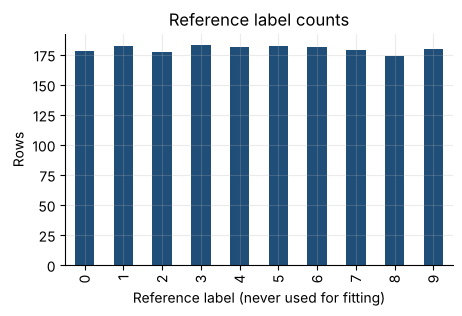

Mean absolute correlation between features: nan


In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.head(15).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pd.Series(y_true).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Reference label (never used for fitting)"); ax.set_ylabel("Rows"); ax.set_title("Reference label counts")
plt.show()
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Mean absolute correlation between features:", round(float(corr.mean()), 3))

## 7. Data Preprocessing

Raw pixel space has 64 dimensions, which makes distances less informative. We project to 10 principal components fitted on all rows (descriptive analysis, no labels).

In [3]:
X = PCA(10, random_state=SEED).fit_transform(X_raw.values)
print("projected shape:", X.shape)

projected shape: (1797, 10)


## 8. Algorithm Implementation

### 8.1 Concept

A dense region is a set of points that all have enough neighbours nearby. Clusters grow by walking from one core point to the next.

### 8.2 Python implementation from scratch

We implement DBSCAN with a neighbour list on 500 rows and compare with scikit-learn at the same settings.

In [4]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
sub = X[:500]
def dbscan_scratch(P, eps, min_pts):
    dist = np.sqrt(((P[:, None] - P[None]) ** 2).sum(axis=2))
    neigh = [np.where(dist[i] <= eps)[0] for i in range(len(P))]
    core = np.array([len(n) >= min_pts for n in neigh])
    labels = -np.ones(len(P), dtype=int)
    cid = 0
    for i in range(len(P)):
        if labels[i] != -1 or not core[i]:
            continue
        labels[i] = cid
        stack = [i]
        while stack:
            p = stack.pop()
            for q in neigh[p]:
                if labels[q] == -1:
                    labels[q] = cid
                    if core[q]:
                        stack.append(q)
        cid += 1
    return labels
eps_try = 20.0
mine = dbscan_scratch(sub, eps_try, 5)
ref = DBSCAN(eps=eps_try, min_samples=5).fit_predict(sub)
print("clusters scratch:", mine.max() + 1, "| sklearn:", ref.max() + 1, "| noise scratch:", int((mine == -1).sum()), "| sklearn:", int((ref == -1).sum()))

clusters scratch: 2 | sklearn: 2 | noise scratch: 2 | sklearn: 2


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `eps` | Neighbourhood radius. |
| `min_samples` | Neighbours needed for a core point. |
| `metric` | Distance function. |

## 9. Model Training

min_samples is set to 10 (twice the 5 usual for low dimensions is not needed here, we check 10 and 5 in an experiment). eps comes from a grid. We pick the eps with the best silhouette among settings that give at least 3 clusters and at most 30 percent noise.

In [5]:
from sklearn.neighbors import NearestNeighbors
MIN_SAMPLES = 10
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
rows = []
for eps in np.linspace(8, 24, 17):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    s = internal_scores(X, lab)
    rows.append({"eps": round(eps, 1), "clusters": s["clusters"], "noise": s["noise_fraction"], "silhouette": s.get("Silhouette", np.nan)})
sweep = pd.DataFrame(rows)
display(sweep.round(3))
ok = sweep[(sweep.clusters >= 3) & (sweep.noise <= 0.30)]
BEST_EPS = float(ok.loc[ok.silhouette.idxmax(), "eps"]) if len(ok) else float(sweep.loc[sweep.silhouette.idxmax(), "eps"])
print("chosen eps:", BEST_EPS)
labels = DBSCAN(eps=BEST_EPS, min_samples=MIN_SAMPLES).fit_predict(X)

,eps,clusters,noise,silhouette
0,8.0,2,0.977,0.740
1,9.0,8,0.892,0.596
2,10.0,11,0.753,0.472
3,11.0,14,0.594,0.435
4,12.0,14,0.410,0.355
5,13.0,12,0.259,0.270
6,14.0,9,0.138,0.162
7,15.0,6,0.068,0.110
8,16.0,2,0.032,0.113
9,17.0,2,0.016,0.112


chosen eps: 13.0


## 10. Evaluation

Internal scores need no labels: silhouette (higher is better, range -1 to 1), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better). External scores (ARI and NMI) compare with a reference label that was never used for fitting. A reference label is not the truth about the data. It is one possible grouping.

In [6]:
METRICS = {**internal_scores(X, labels)}
mask = labels != -1
if mask.sum() > 1 and len(np.unique(labels[mask])) > 1:
    METRICS.update({k + "_nonnoise": v for k, v in external_scores(y_true[mask], labels[mask]).items()})
CONFIG = {"eps": BEST_EPS, "min_samples": MIN_SAMPLES, "pca_components": 10}
EXTRA = {"sweep": sweep.round(4).to_dict("records")}
print("external scores are computed on non noise rows only")

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="DBSCAN", dataset="digits",
                          task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

external scores are computed on non noise rows only
saved: experiments/results/dbscan.json


,metric
clusters,12.0000
noise_fraction,0.2588
Silhouette,0.2700
Davies_Bouldin,1.2293
Calinski_Harabasz,210.9883
ARI_nonnoise,0.8062
NMI_nonnoise,0.9021


## 11. Visualization

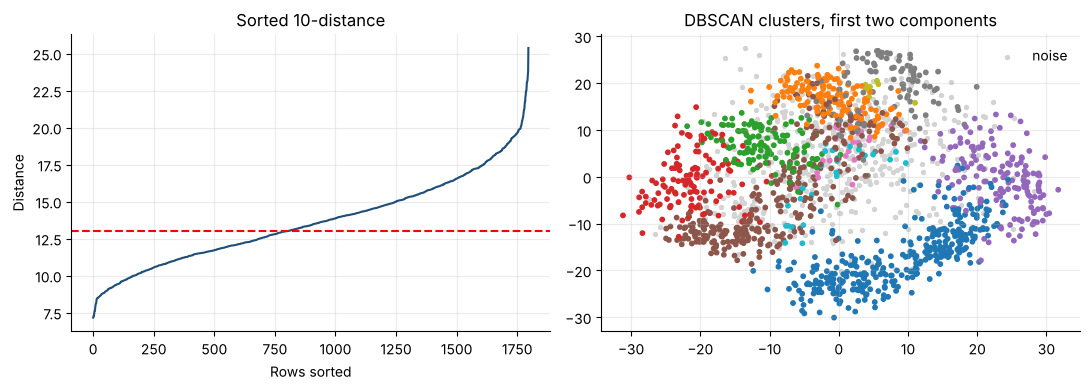

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(kdist); axes[0].axhline(BEST_EPS, color="red", linestyle="--"); axes[0].set_title(f"Sorted {MIN_SAMPLES}-distance"); axes[0].set_xlabel("Rows sorted"); axes[0].set_ylabel("Distance")
Z = PCA(2, random_state=SEED).fit_transform(X)
axes[1].scatter(Z[labels == -1, 0], Z[labels == -1, 1], c="lightgray", s=8, label="noise")
axes[1].scatter(Z[labels != -1, 0], Z[labels != -1, 1], c=labels[labels != -1], cmap="tab10", s=10)
axes[1].set_title("DBSCAN clusters, first two components"); axes[1].legend()
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "overview"); plt.show()

## 12. Interpretation

Noise rows are the digits the algorithm could not place in a dense group. Look at a few of them.

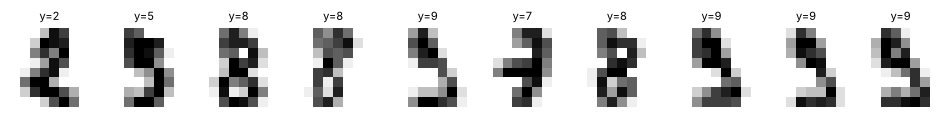

noise rows by reference digit: {0: 9, 1: 62, 2: 48, 3: 60, 4: 23, 5: 42, 6: 16, 7: 35, 8: 105, 9: 65}


In [8]:
noise_idx = np.where(labels == -1)[0][:10]
fig, axes = plt.subplots(1, len(noise_idx), figsize=(12, 1.6))
for ax, i in zip(np.atleast_1d(axes), noise_idx):
    ax.imshow(X_raw.values[i].reshape(8, 8), cmap="gray_r"); ax.axis("off"); ax.set_title(f"y={y_true.iloc[i]}", fontsize=8)
plt.show()
print("noise rows by reference digit:", pd.Series(y_true[labels == -1]).value_counts().sort_index().to_dict())

## 13. Experiments and Challenges

### Experiment 1: Sensitivity to eps

A small change in eps can merge or split clusters.

In [9]:
for eps in [BEST_EPS - 2, BEST_EPS, BEST_EPS + 2]:
    s = internal_scores(X, DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X))
    print(f"eps={eps:.1f}: clusters {s['clusters']}, noise {s['noise_fraction']:.2f}")

eps=11.0: clusters 14, noise 0.59
eps=13.0: clusters 12, noise 0.26
eps=15.0: clusters 6, noise 0.07


### Experiment 2: Dimensionality

Run DBSCAN on 2, 10, 30 and 64 dimensions with eps rescaled by the median neighbour distance.

In [10]:
for d in [2, 10, 30]:
    P = PCA(d, random_state=SEED).fit_transform(X_raw.values)
    med = np.median(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(P).kneighbors(P)[0][:, -1])
    s = internal_scores(P, DBSCAN(eps=med * 1.1, min_samples=MIN_SAMPLES).fit_predict(P))
    print(f"{d} components: clusters {s['clusters']}, noise {s['noise_fraction']:.2f}")

2 components: clusters 8, noise 0.19


10 components: clusters 8, noise 0.08


30 components: clusters 8, noise 0.08


### Experiment 3: min_samples

Higher min_samples marks more points as noise.

In [11]:
for m in [3, 5, 10, 20]:
    s = internal_scores(X, DBSCAN(eps=BEST_EPS, min_samples=m).fit_predict(X))
    print(f"min_samples={m}: clusters {s['clusters']}, noise {s['noise_fraction']:.2f}")

min_samples=3: clusters 15, noise 0.07


min_samples=5: clusters 15, noise 0.11
min_samples=10: clusters 12, noise 0.26


min_samples=20: clusters 11, noise 0.52


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

Schubert et al. stress that DBSCAN works with one global density and that parameter choice matters. Our eps sweep and the dimension experiment show the same sensitivity on digit data.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use HDBSCAN for varying density, and evaluate stability across resamples.

**Research limitations.** One dataset and one seed for the headline numbers. 

## 15. Summary and Further Reading

**Key takeaways**

- eps and min_samples define density.
- Noise is a result, not a failure.
- Reduce dimension first.

**Use cases.** Spatial data, anomaly review, arbitrary shaped clusters.

**Limitations.** One global density, high dimension sensitivity.

**Recommended next notebook.** HDBSCAN.

**Further reading.** See `references.md` in this folder.